In [ ]:
import os
import time
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Tekrarlanabilirlik için sabit tohum (seed)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# GPU Kontrolü
gpus = tf.config.list_physical_devices('GPU')
print("TensorFlow Sürümü:", tf.__version__)
print("Kullanılabilir GPU:", gpus if gpus else "YOK (CPU kullanılıyor!)")

TensorFlow Sürümü: 2.21.0
Kullanılabilir GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import kagglehub

# Veri kümesini indir
dataset_path = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print("Veri kümesi yolu:", dataset_path)
print("İçerik:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Veri kümesi yolu: /kaggle/input/gtsrb-german-traffic-sign
İçerik: ['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']


In [ ]:
IMG_SIZE = 64
NUM_CLASSES = 43

# Train.csv dosyasını oku
train_df = pd.read_csv(os.path.join(dataset_path, "Train.csv"))
print(f"Toplam görüntü sayısı: {len(train_df)}")
print(f"Sınıf sayısı: {train_df['ClassId'].nunique()}")

# Görüntüleri ve etiketleri belleğe yükle
images = []
labels = train_df["ClassId"].values

start_time = time.time()
for img_rel_path in train_df["Path"]:
    img_full_path = os.path.join(dataset_path, img_rel_path)
    img = cv2.imread(img_full_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # OpenCV BGR okur, RGB'ye çeviriyoruz
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    images.append(img)

# NumPy dizisine dönüştür ve [0, 1] aralığına normalize et (float32 RAM dostudur)
X = np.array(images, dtype=np.float32) / 255.0
y = np.array(labels, dtype=np.int32)

print(f"Yükleme süresi: {time.time() - start_time:.2f} saniye")
print(f"X boyutu: {X.shape}, y boyutu: {y.shape}")

# 1. Aşama: %10 Bağımsız Test Kümesini ayır (3.921 örnek — Proje 1 ile birebir aynı boyut)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.10, random_state=SEED, stratify=y
)

# 2. Aşama: Kalan %90'lık kısmı %80 Eğitim ve %10 Doğrulama olacak şekilde böl (1/9 ≈ 0.1111)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1/9, random_state=SEED, stratify=y_temp
)

# Belleği rahatlatmak için ara değişkenleri temizle
del images, X, X_temp, y_temp

print("\n--- Veri Kümesi Bölünme Özeti ---")
print(f"Eğitim (Train)     : {X_train.shape} | Etiket: {y_train.shape}")
print(f"Doğrulama (Val)    : {X_val.shape} | Etiket: {y_val.shape}")
print(f"Test (Bağımsız)    : {X_test.shape} | Etiket: {y_test.shape}")

Toplam görüntü sayısı: 39209
Sınıf sayısı: 43
Yükleme süresi: 181.47 saniye
X boyutu: (39209, 64, 64, 3), y boyutu: (39209,)

--- Veri Kümesi Bölünme Özeti ---
Eğitim (Train)     : (31367, 64, 64, 3) | Etiket: (31367,)
Doğrulama (Val)    : (3921, 64, 64, 3) | Etiket: (3921,)
Test (Bağımsız)    : (3921, 64, 64, 3) | Etiket: (3921,)


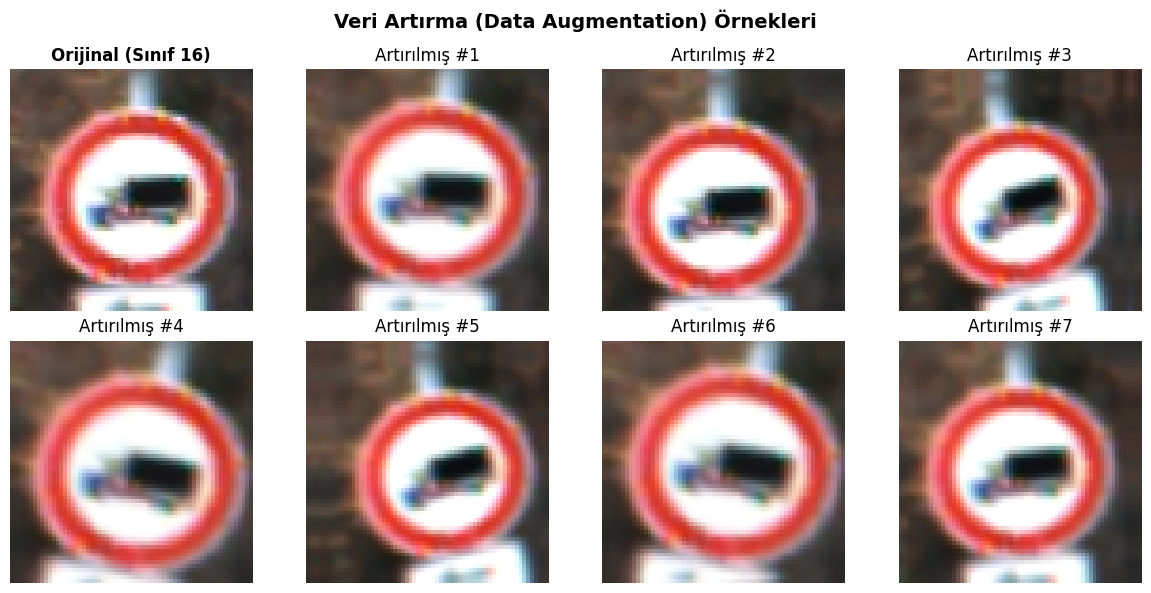

Veri artırma bloğu ve tf.data hatları başarıyla oluşturuldu.


In [ ]:
# Trafik levhalarına uygun Veri Artırma (Yatay/dikey çevirme semantik bozulma nedeniyle eklenmemiştir)
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.04, seed=SEED),              # Yaklaşık ±14 derece döndürme
    layers.RandomZoom(0.10, seed=SEED),                  # %10 yakınlaştırma / ölçeklendirme
    layers.RandomTranslation(0.05, 0.05, seed=SEED),     # %5 yatay/dikey kaydırma
    layers.RandomContrast(0.10, seed=SEED),              # Aydınlatma/kontrast değişimi
], name="data_augmentation")

# Rapor için Veri Artırma Görselleştirmesi (1 Orijinal + 7 Artırılmış Örnek)
sample_idx = 100  # Farklı bir levha görmek istersen bu indeksi değiştirebilirsin
sample_img = X_train[sample_idx]
sample_label = y_train[sample_idx]

plt.figure(figsize=(12, 6))
plt.subplot(2, 4, 1)
plt.imshow(sample_img)
plt.title(f"Orijinal (Sınıf {sample_label})", fontweight="bold")
plt.axis("off")

for i in range(2, 9):
    aug_img = data_augmentation(tf.expand_dims(sample_img, 0), training=True)
    plt.subplot(2, 4, i)
    plt.imshow(np.clip(aug_img[0].numpy(), 0, 1))
    plt.title(f"Artırılmış #{i-1}")
    plt.axis("off")

plt.suptitle("Veri Artırma (Data Augmentation) Örnekleri", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("sekil1_veri_artirma.png", dpi=300, bbox_inches="tight")
plt.show()

# GPU için hızlı tf.data.Dataset hatları
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.shuffle(buffer_size=len(X_train), seed=SEED).batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("Veri artırma bloğu ve tf.data hatları başarıyla oluşturuldu.")

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,097,40

 Total params: 2,398,283 (9.15 MB)

 Trainable params: 2,396,875 (9.14 MB)

 Non-trainable params: 1,408 (5.50 KB)

Epoch 1/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 39s 55ms/step - accuracy: 0.7197 - loss: 1.0354 - val_accuracy: 0.8526 - val_loss: 0.4710 - learning_rate: 0.0010
Epoch 2/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 25s 52ms/step - accuracy: 0.9638 - loss: 0.1355 - val_accuracy: 0.9954 - val_loss: 0.0224 - learning_rate: 0.0010
Epoch 3/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 41s 52ms/step - accuracy: 0.9802 - loss: 0.0728 - val_accuracy: 0.9972 - val_loss: 0.0156 - learning_rate: 0.0010
Epoch 4/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 26s 52ms/step - accuracy: 0.9857 - loss: 0.0524 - val_accuracy: 0.9969 - val_loss: 0.0103 - learning_rate: 0.0010
Epoch 5/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 26s 52ms/step - accuracy: 0.9894 - loss: 0.0381 - val_accuracy: 0.9995 - val_loss: 0.0046 - learning_rate: 0.0010
Epoch 6/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 26s 53ms/step - accuracy: 0.9907 - loss: 0.0321 - val_accuracy: 0.9964 - val_loss: 0.0115 - learning_rate: 0.0010
Epoch 7/30
491/491 ━━━━━━━━━━━━━━━━━━━━ 26s 53ms/step - accuracy: 0.9908 - l

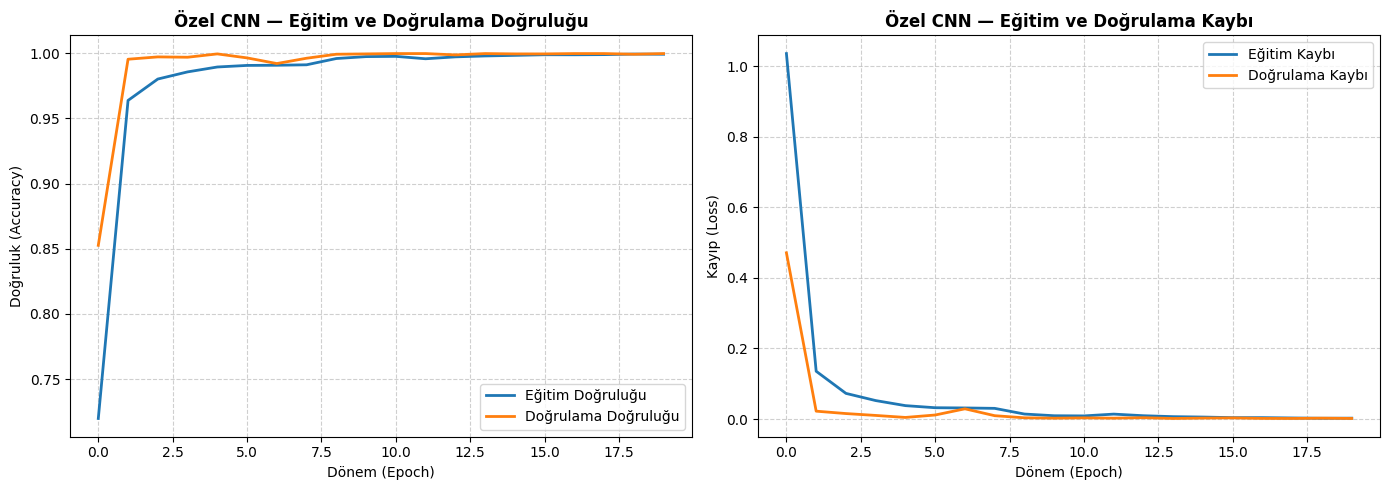

In [ ]:
def build_custom_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    inputs = keras.Input(shape=input_shape)

    # Veri artırma yalnızca eğitim sırasında aktif olur
    x = data_augmentation(inputs)

    # Blok 1: 32 Filtre
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.20)(x)

    # Blok 2: 64 Filtre
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Blok 3: 128 Filtre
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.30)(x)

    # Tam Bağlantılı (Fully Connected) Katmanlar
    x = layers.Flatten()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.50)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="Custom_CNN")
    return model

custom_cnn = build_custom_cnn()
custom_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
custom_cnn.summary()

# Geri çağırmalar (Callbacks)
callbacks_custom = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1
    )
]

# Eğitim ve süre ölçümü
EPOCHS = 30
start_train = time.time()
history_custom = custom_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks_custom,
    verbose=1
)
custom_train_time = time.time() - start_train
print(f"\nÖzel CNN Eğitim Süresi: {custom_train_time:.2f} saniye")

# Eğitim / Doğrulama Eğrileri (Rapor Görseli)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Doğruluk (Accuracy)
axes[0].plot(history_custom.history["accuracy"], label="Eğitim Doğruluğu", linewidth=2)
axes[0].plot(history_custom.history["val_accuracy"], label="Doğrulama Doğruluğu", linewidth=2)
axes[0].set_title("Özel CNN — Eğitim ve Doğrulama Doğruluğu", fontweight="bold")
axes[0].set_xlabel("Dönem (Epoch)")
axes[0].set_ylabel("Doğruluk (Accuracy)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

# Kayıp (Loss)
axes[1].plot(history_custom.history["loss"], label="Eğitim Kaybı", linewidth=2)
axes[1].plot(history_custom.history["val_loss"], label="Doğrulama Kaybı", linewidth=2)
axes[1].set_title("Özel CNN — Eğitim ve Doğrulama Kaybı", fontweight="bold")
axes[1].set_xlabel("Dönem (Epoch)")
axes[1].set_ylabel("Kayıp (Loss)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("sekil2_custom_cnn_egitim_egrileri.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Test kümesi üzerinde tahmin ve çıkarım (inference) süresi ölçümü
start_inf = time.time()
y_pred_probs_custom = custom_cnn.predict(test_ds, verbose=0)
custom_inf_time = time.time() - start_inf
y_pred_custom = np.argmax(y_pred_probs_custom, axis=1)

# Temel metrikler
acc_custom = accuracy_score(y_test, y_pred_custom)
prec_macro_custom = precision_score(y_test, y_pred_custom, average="macro")
rec_macro_custom = recall_score(y_test, y_pred_custom, average="macro")
f1_macro_custom = f1_score(y_test, y_pred_custom, average="macro")
f1_weighted_custom = f1_score(y_test, y_pred_custom, average="weighted")

print("==========================================")
print("   ÖZEL CNN — BAĞIMSIZ TEST SONUÇLARI")
print("==========================================")
print(f"Test Doğruluğu (Accuracy) : {acc_custom * 100:.2f}%")
print(f"Makro Kesinlik (Precision): {prec_macro_custom * 100:.2f}%")
print(f"Makro Duyarlılık (Recall) : {rec_macro_custom * 100:.2f}%")
print(f"Makro F1-Skoru            : {f1_macro_custom * 100:.2f}%")
print(f"Ağırlıklı F1-Skoru        : {f1_weighted_custom * 100:.2f}%")
print(f"Eğitim Süresi             : {custom_train_time:.2f} saniye")
print(f"Test Çıkarım Süresi       : {custom_inf_time:.2f} saniye (3.921 örnek)")
print("==========================================\n")

# Sınıflandırma Raporu
report_custom = classification_report(y_test, y_pred_custom, digits=4)
print(report_custom)

   ÖZEL CNN — BAĞIMSIZ TEST SONUÇLARI
Test Doğruluğu (Accuracy) : 99.92%
Makro Kesinlik (Precision): 99.94%
Makro Duyarlılık (Recall) : 99.97%
Makro F1-Skoru            : 99.95%
Ağırlıklı F1-Skoru        : 99.92%
Eğitim Süresi             : 550.80 saniye
Test Çıkarım Süresi       : 0.78 saniye (3.921 örnek)

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        21
           1     1.0000    1.0000    1.0000       222
           2     1.0000    0.9956    0.9978       225
           3     1.0000    1.0000    1.0000       141
           4     0.9949    0.9949    0.9949       198
           5     1.0000    1.0000    1.0000       186
           6     1.0000    1.0000    1.0000        42
           7     1.0000    1.0000    1.0000       144
           8     0.9930    1.0000    0.9965       141
           9     1.0000    1.0000    1.0000       147
          10     1.0000    1.0000    1.0000       201
          11     1.0000    1.0000    1.00

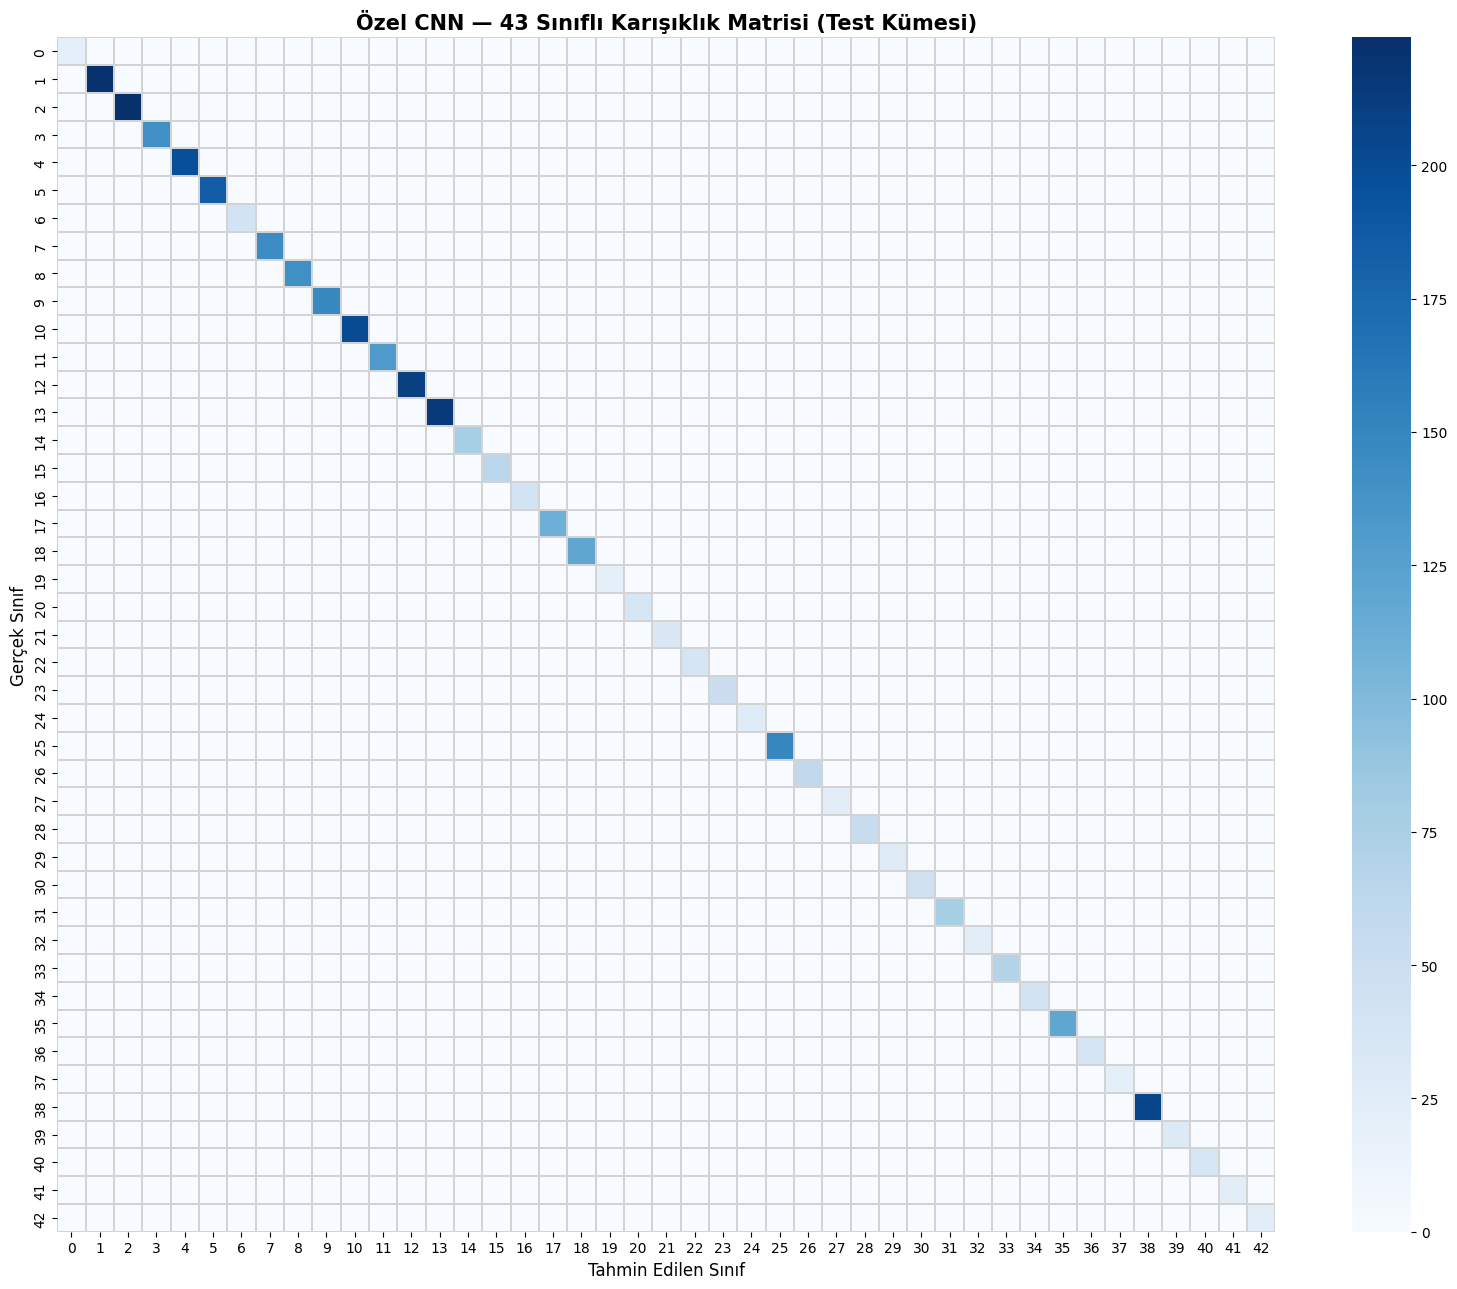

In [ ]:
cm_custom = confusion_matrix(y_test, y_pred_custom)
plt.figure(figsize=(16, 13))
sns.heatmap(cm_custom, cmap="Blues", annot=False, cbar=True, linewidths=0.2, linecolor="lightgray")
plt.title("Özel CNN — 43 Sınıflı Karışıklık Matrisi (Test Kümesi)", fontsize=15, fontweight="bold")
plt.xlabel("Tahmin Edilen Sınıf", fontsize=12)
plt.ylabel("Gerçek Sınıf", fontsize=12)
plt.tight_layout()
plt.savefig("sekil3_custom_cnn_karisiklik_matrisi.png", dpi=300, bbox_inches="tight")
plt.show()

Toplam hatalı tahmin sayısı: 3 / 3921


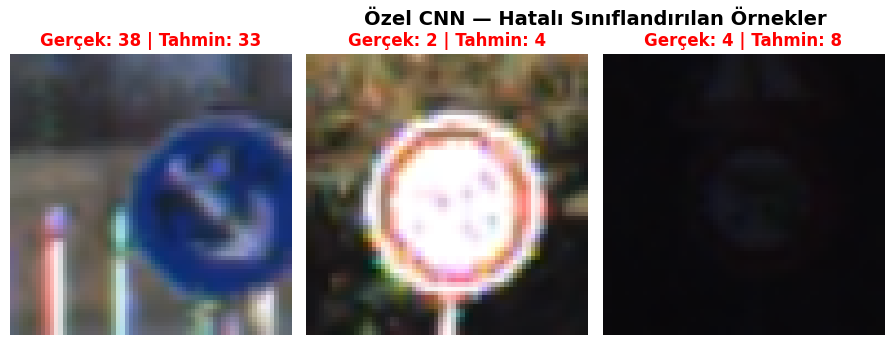

In [ ]:
wrong_indices = np.where(y_pred_custom != y_test)[0]
print(f"Toplam hatalı tahmin sayısı: {len(wrong_indices)} / {len(y_test)}")

if len(wrong_indices) > 0:
    n_show = min(8, len(wrong_indices))
    cols = 4
    rows = int(np.ceil(n_show / cols))
    plt.figure(figsize=(12, 3.5 * rows))
    for i, idx in enumerate(wrong_indices[:n_show]):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(X_test[idx])
        plt.title(f"Gerçek: {y_test[idx]} | Tahmin: {y_pred_custom[idx]}", color="red", fontweight="bold")
        plt.axis("off")
    plt.suptitle("Özel CNN — Hatalı Sınıflandırılan Örnekler", fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig("sekil4_custom_cnn_hatali_ornekler.png", dpi=300, bbox_inches="tight")
    plt.show()

In [ ]:
from tensorflow.keras.applications import MobileNetV2

def build_mobilenetv2(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES):
    inputs = keras.Input(shape=input_shape)
    x = data_augmentation(inputs)
    x = layers.Rescaling(scale=2.0, offset=-1.0)(x)  # [0, 1] -> [-1, 1]

    base_model = MobileNetV2(
        input_shape=input_shape,
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False  # 1. Aşama: Omurga dondurulur

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.40)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="MobileNetV2_Transfer"), base_model

mobilenet_model, base_model = build_mobilenetv2()

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("1. Aşama: Özellik Çıkarımı (Feature Extraction) başlıyor...")
start_train_mb = time.time()
history_mb_stage1 = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    verbose=1
)

/tmp/ipykernel_339/2662766609.py:8: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1. Aşama: Özellik Çıkarımı (Feature Extraction) başlıyor...
Epoch 1/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 19s 24ms/step - accuracy: 0.4551 - loss: 1.8952 - val_accuracy: 0.6480 - val_loss: 1.0991
Epoch 2/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.5851 - loss: 1.2842 - val_accuracy: 0.7021 - val_loss: 0.9324
Epoch 3/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.6180 - loss: 1.1560 - val_accuracy: 0.7238 - val_loss: 0.8496
Epoch 4/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 9s 19ms/step - accuracy: 0.6443 - loss: 1.0721 - val_accuracy: 0.7355 - val_loss: 0.8111
Epoch 5/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - accuracy: 0.6617 - loss: 1.0164 - val_accuracy: 0.7478 - val_loss: 0.7748


In [ ]:
# Son 40 katmanı eğitime aç
base_model.trainable = True
for layer in base_model.layers[:-40]:
    layer.trainable = False

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks_mb = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
    )
]

print("2. Aşama: İnce Ayar (Fine-Tuning) başlıyor...")
history_mb_stage2 = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_mb,
    verbose=1
)

mobilenet_train_time = time.time() - start_train_mb
print(f"\nMobileNetV2 Toplam Eğitim Süresi: {mobilenet_train_time:.2f} saniye")

2. Aşama: İnce Ayar (Fine-Tuning) başlıyor...
Epoch 1/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 33s 40ms/step - accuracy: 0.5388 - loss: 1.4977 - val_accuracy: 0.5726 - val_loss: 1.5111 - learning_rate: 1.0000e-04
Epoch 2/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - accuracy: 0.7195 - loss: 0.8350 - val_accuracy: 0.7475 - val_loss: 0.7468 - learning_rate: 1.0000e-04
Epoch 3/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - accuracy: 0.8051 - loss: 0.5829 - val_accuracy: 0.8646 - val_loss: 0.4069 - learning_rate: 1.0000e-04
Epoch 4/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 19s 39ms/step - accuracy: 0.8574 - loss: 0.4358 - val_accuracy: 0.9003 - val_loss: 0.3048 - learning_rate: 1.0000e-04
Epoch 5/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - accuracy: 0.8906 - loss: 0.3369 - val_accuracy: 0.9276 - val_loss: 0.2114 - learning_rate: 1.0000e-04
Epoch 6/15
491/491 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.9122 - loss: 0.2722 - val_accuracy: 0.9365 - val_loss: 0.1835 - learning_rate: 1.0000e-04
Epoch 

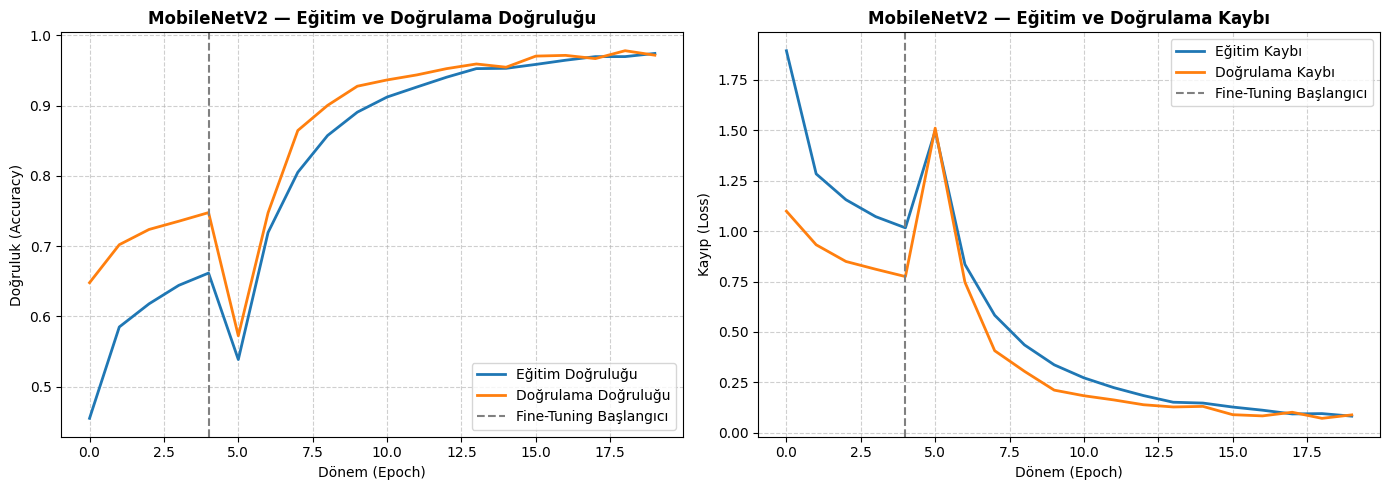

In [ ]:
# İki aşamanın geçmişini birleştir
acc_mb = history_mb_stage1.history["accuracy"] + history_mb_stage2.history["accuracy"]
val_acc_mb = history_mb_stage1.history["val_accuracy"] + history_mb_stage2.history["val_accuracy"]
loss_mb = history_mb_stage1.history["loss"] + history_mb_stage2.history["loss"]
val_loss_mb = history_mb_stage1.history["val_loss"] + history_mb_stage2.history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(acc_mb, label="Eğitim Doğruluğu", linewidth=2)
axes[0].plot(val_acc_mb, label="Doğrulama Doğruluğu", linewidth=2)
axes[0].axvline(x=4, color="gray", linestyle="--", label="Fine-Tuning Başlangıcı")
axes[0].set_title("MobileNetV2 — Eğitim ve Doğrulama Doğruluğu", fontweight="bold")
axes[0].set_xlabel("Dönem (Epoch)")
axes[0].set_ylabel("Doğruluk (Accuracy)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

axes[1].plot(loss_mb, label="Eğitim Kaybı", linewidth=2)
axes[1].plot(val_loss_mb, label="Doğrulama Kaybı", linewidth=2)
axes[1].axvline(x=4, color="gray", linestyle="--", label="Fine-Tuning Başlangıcı")
axes[1].set_title("MobileNetV2 — Eğitim ve Doğrulama Kaybı", fontweight="bold")
axes[1].set_xlabel("Dönem (Epoch)")
axes[1].set_ylabel("Kayıp (Loss)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("sekil5_mobilenetv2_egitim_egrileri.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
start_inf_mb = time.time()
y_pred_probs_mb = mobilenet_model.predict(test_ds, verbose=0)
mobilenet_inf_time = time.time() - start_inf_mb
y_pred_mb = np.argmax(y_pred_probs_mb, axis=1)

acc_mb_test = accuracy_score(y_test, y_pred_mb)
prec_macro_mb = precision_score(y_test, y_pred_mb, average="macro")
rec_macro_mb = recall_score(y_test, y_pred_mb, average="macro")
f1_macro_mb = f1_score(y_test, y_pred_mb, average="macro")
f1_weighted_mb = f1_score(y_test, y_pred_mb, average="weighted")

print("============================================")
print("  MOBILENETV2 — BAĞIMSIZ TEST SONUÇLARI")
print("============================================")
print(f"Test Doğruluğu (Accuracy) : {acc_mb_test * 100:.2f}%")
print(f"Makro Kesinlik (Precision): {prec_macro_mb * 100:.2f}%")
print(f"Makro Duyarlılık (Recall) : {rec_macro_mb * 100:.2f}%")
print(f"Makro F1-Skoru            : {f1_macro_mb * 100:.2f}%")
print(f"Ağırlıklı F1-Skoru        : {f1_weighted_mb * 100:.2f}%")
print(f"Toplam Eğitim Süresi      : {mobilenet_train_time:.2f} saniye")
print(f"Test Çıkarım Süresi       : {mobilenet_inf_time:.2f} saniye (3.921 örnek)")
print("============================================\n")

print(f"Toplam hatalı tahmin sayısı: {np.sum(y_pred_mb != y_test)} / {len(y_test)}")

  MOBILENETV2 — BAĞIMSIZ TEST SONUÇLARI
Test Doğruluğu (Accuracy) : 97.60%
Makro Kesinlik (Precision): 98.05%
Makro Duyarlılık (Recall) : 97.57%
Makro F1-Skoru            : 97.77%
Ağırlıklı F1-Skoru        : 97.60%
Toplam Eğitim Süresi      : 370.46 saniye
Test Çıkarım Süresi       : 4.16 saniye (3.921 örnek)

Toplam hatalı tahmin sayısı: 94 / 3921


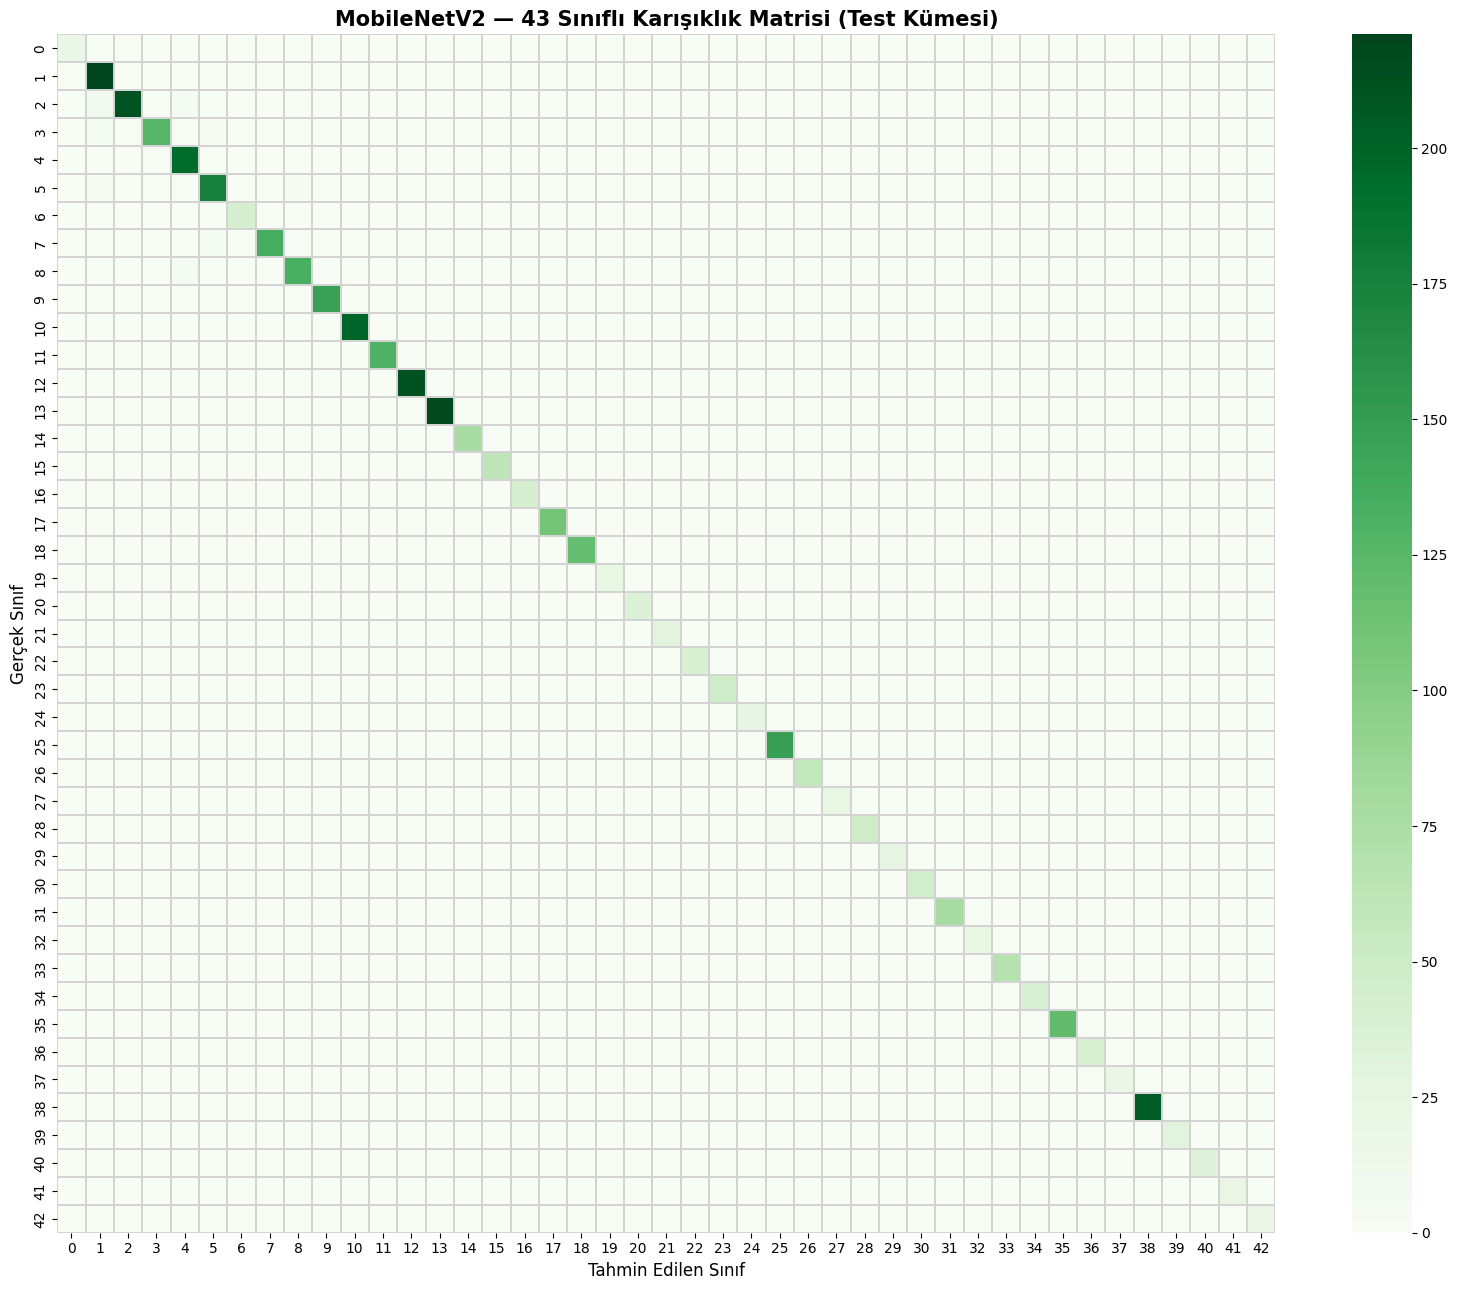

In [ ]:
cm_mb = confusion_matrix(y_test, y_pred_mb)
plt.figure(figsize=(16, 13))
sns.heatmap(cm_mb, cmap="Greens", annot=False, cbar=True, linewidths=0.2, linecolor="lightgray")
plt.title("MobileNetV2 — 43 Sınıflı Karışıklık Matrisi (Test Kümesi)", fontsize=15, fontweight="bold")
plt.xlabel("Tahmin Edilen Sınıf", fontsize=12)
plt.ylabel("Gerçek Sınıf", fontsize=12)
plt.tight_layout()
plt.savefig("sekil6_mobilenetv2_karisiklik_matrisi.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Proje 1 (SVM) ve Proje 2 (Özel CNN & MobileNetV2) Karşılaştırma Özeti
karsilastirma_df = pd.DataFrame({
    "Model": [
        "SVM (Proje 1 — HOG + LBP)",
        "MobileNetV2 (Proje 2 — Transfer Öğrenme)",
        "Özel CNN (Proje 2 — Sıfırdan Mimari)"
    ],
    "Test Doğruluğu (%)": [
        98.72,
        round(acc_mb_test * 100, 2),
        round(acc_custom * 100, 2)
    ],
    "Makro Kesinlik (%)": [
        "-",
        round(prec_macro_mb * 100, 2),
        round(prec_macro_custom * 100, 2)
    ],
    "Makro Duyarlılık (%)": [
        "-",
        round(rec_macro_mb * 100, 2),
        round(rec_macro_custom * 100, 2)
    ],
    "Makro F1 (%)": [
        "-",
        round(f1_macro_mb * 100, 2),
        round(f1_macro_custom * 100, 2)
    ],
    "Eğitim Süresi (sn)": [
        "-",
        round(mobilenet_train_time, 2),
        round(custom_train_time, 2)
    ],
    "Test Çıkarım Süresi (sn)": [
        "-",
        round(mobilenet_inf_time, 2),
        round(custom_inf_time, 2)
    ]
})

print(karsilastirma_df.to_string(index=False))

                                   Model  Test Doğruluğu (%) Makro Kesinlik (%) Makro Duyarlılık (%) Makro F1 (%) Eğitim Süresi (sn) Test Çıkarım Süresi (sn)
               SVM (Proje 1 — HOG + LBP)               98.72                  -                    -            -                  -                        -
MobileNetV2 (Proje 2 — Transfer Öğrenme)               97.60              98.05                97.57        97.77             370.46                     4.16
    Özel CNN (Proje 2 — Sıfırdan Mimari)               99.92              99.94                99.97        99.95              550.8                     0.78


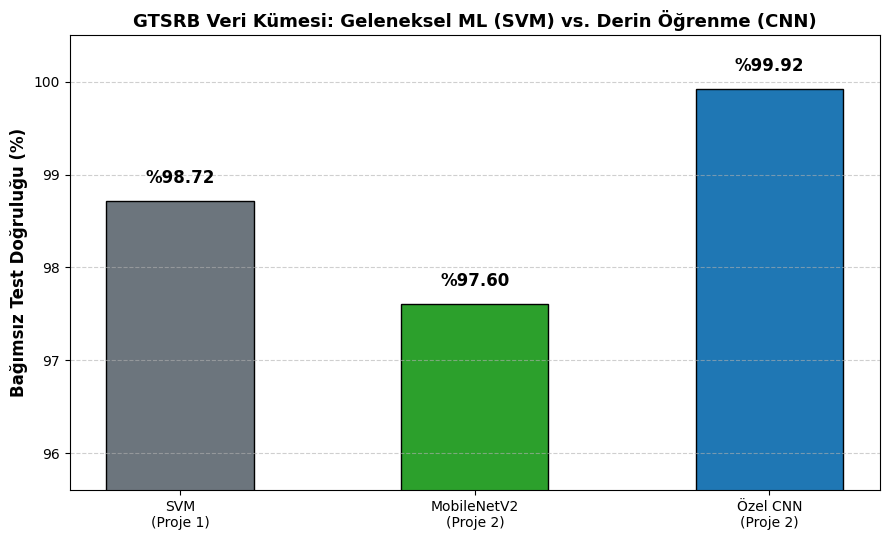

In [ ]:
modeller = ["SVM\n(Proje 1)", "MobileNetV2\n(Proje 2)", "Özel CNN\n(Proje 2)"]
dogruluklar = [98.72, acc_mb_test * 100, acc_custom * 100]
renkler = ["#6c757d", "#2ca02c", "#1f77b4"]

plt.figure(figsize=(9, 5.5))
bars = plt.bar(modeller, dogruluklar, color=renkler, width=0.5, edgecolor="black")

# Y eksenini farkı net gösterecek şekilde ayarla
plt.ylim(min(dogruluklar) - 2.0, 100.5)
plt.ylabel("Bağımsız Test Doğruluğu (%)", fontsize=12, fontweight="bold")
plt.title("GTSRB Veri Kümesi: Geleneksel ML (SVM) vs. Derin Öğrenme (CNN)", fontsize=13, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.6)

# Çubukların üzerine değerleri yazdır
for bar, val in zip(bars, dogruluklar):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.15,
        f"%{val:.2f}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.tight_layout()
plt.savefig("sekil7_proje1_vs_proje2_karsilastirma.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

# Her iki modelin sınıf bazlı F1-skorlarını sözlük olarak al
rep_custom = classification_report(y_test, y_pred_custom, output_dict=True)
rep_mb = classification_report(y_test, y_pred_mb, output_dict=True)

# Hız sınırı levhaları (Özellikle Proje 1'de SVM'in en zayıf olduğu Sınıf 5)
hedef_siniflar = {
    "0": "20 km/s",
    "1": "30 km/s",
    "2": "50 km/s",
    "3": "60 km/s",
    "4": "70 km/s",
    "5": "80 km/s (SVM En Zayıf: 0.9348)",
    "7": "100 km/s",
    "8": "120 km/s"
}

satirlar = []
for sinif_id, aciklama in hedef_siniflar.items():
    satirlar.append({
        "Sınıf": f"Sınıf {sinif_id} ({aciklama})",
        "Özel CNN F1": round(rep_custom[sinif_id]["f1-score"], 4),
        "MobileNetV2 F1": round(rep_mb[sinif_id]["f1-score"], 4),
        "Test Örnek Sayısı": int(rep_custom[sinif_id]["support"])
    })

hiz_df = pd.DataFrame(satirlar)
print("=== HIZ SINIRI LEVHALARI F1-SKORU KARŞILAŞTIRMASI ===")
print(hiz_df.to_string(index=False))

=== HIZ SINIRI LEVHALARI F1-SKORU KARŞILAŞTIRMASI ===
                                   Sınıf  Özel CNN F1  MobileNetV2 F1  Test Örnek Sayısı
                       Sınıf 0 (20 km/s)       1.0000          0.9524                 21
                       Sınıf 1 (30 km/s)       1.0000          0.9465                222
                       Sınıf 2 (50 km/s)       0.9978          0.9567                225
                       Sınıf 3 (60 km/s)       1.0000          0.9333                141
                       Sınıf 4 (70 km/s)       0.9949          0.9580                198
Sınıf 5 (80 km/s (SVM En Zayıf: 0.9348))       1.0000          0.9462                186
                      Sınıf 7 (100 km/s)       1.0000          0.9677                144
                      Sınıf 8 (120 km/s)       0.9965          0.9537                141


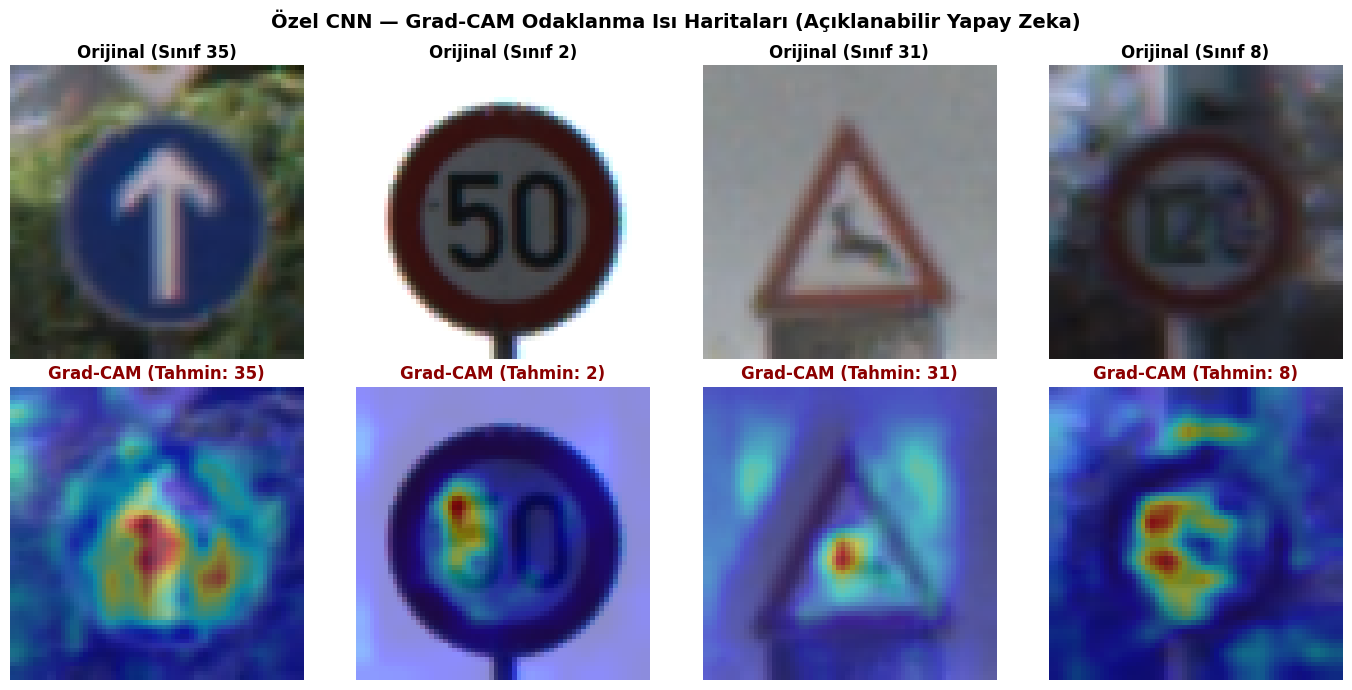

In [ ]:
# 10B (Düzeltilmiş): Net Grad-CAM Isı Haritaları (Logits üzerinden)
last_conv_layer_name = [
    layer.name for layer in custom_cnn.layers if isinstance(layer, layers.Conv2D)
][-1]

def make_gradcam_heatmap(img_array, model, last_conv_name):
    # Softmax doygunluğunu aşmak için son Dense katmanının ağırlıklarını doğrudan kullanıyoruz
    grad_model = keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_name).output, model.layers[-2].output, model.output]
    )
    last_dense_weights = model.layers[-1].weights[0]

    with tf.GradientTape() as tape:
        conv_outputs, penultimate_out, predictions = grad_model(img_array, training=False)
        pred_index = tf.argmax(predictions[0])
        # Softmax öncesi ham skor (logit) üzerinden gradyan al
        logits = tf.matmul(penultimate_out, last_dense_weights)
        class_channel = logits[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)

# 4 farklı sınıftan örnek seç
ornek_indeksler = [10, 120, 250, 300]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, idx in enumerate(ornek_indeksler):
    img = X_test[idx]
    true_label = y_test[idx]
    img_input = np.expand_dims(img, axis=0)

    heatmap, pred_label = make_gradcam_heatmap(img_input, custom_cnn, last_conv_layer_name)

    heatmap_resized = cv2.resize(heatmap, (IMG_SIZE, IMG_SIZE))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB) / 255.0
    superimposed = np.clip(0.55 * img + 0.45 * heatmap_colored, 0, 1)

    axes[0, i].imshow(img)
    axes[0, i].set_title(f"Orijinal (Sınıf {true_label})", fontweight="bold")
    axes[0, i].axis("off")

    axes[1, i].imshow(superimposed)
    axes[1, i].set_title(f"Grad-CAM (Tahmin: {pred_label})", color="darkred", fontweight="bold")
    axes[1, i].axis("off")

plt.suptitle("Özel CNN — Grad-CAM Odaklanma Isı Haritaları (Açıklanabilir Yapay Zeka)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("sekil8_gradcam_isi_haritasi.png", dpi=300, bbox_inches="tight")
plt.show()